In [1]:
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm as tq

In [2]:
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [3]:
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Rescaling
from tensorflow.keras.layers import RandomRotation, RandomTranslation, RandomZoom, RandomFlip
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau

In [4]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [5]:
# Setingan Manual Model
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 123
RANDOM_STATE = 42

In [7]:
from google.colab import files
files.view("/content/drive/MyDrive/DEEP_LEARNING/kaggle.json")

<IPython.core.display.Javascript object>

In [8]:
!kaggle datasets download -d smaranjitghose/corn-or-maize-leaf-disease-dataset
!unzip corn-or-maize-leaf-disease-dataset.zip

Dataset URL: https://www.kaggle.com/datasets/smaranjitghose/corn-or-maize-leaf-disease-dataset
License(s): copyright-authors
100% 161M/161M [00:01<00:00, 94.2MB/s]

Archive:  corn-or-maize-leaf-disease-dataset.zip
  inflating: data/Blight/Corn_Blight (1).jpeg  
  inflating: data/Blight/Corn_Blight (1).jpg  
  inflating: data/Blight/Corn_Blight (10).jpg  
  inflating: data/Blight/Corn_Blight (100).jpg  
  inflating: data/Blight/Corn_Blight (1000).JPG  
  inflating: data/Blight/Corn_Blight (1001).JPG  
  inflating: data/Blight/Corn_Blight (1002).JPG  
  inflating: data/Blight/Corn_Blight (1003).JPG  
  inflating: data/Blight/Corn_Blight (1004).JPG  
  inflating: data/Blight/Corn_Blight (1005).JPG  
  inflating: data/Blight/Corn_Blight (1006).JPG  
  inflating: data/Blight/Corn_Blight (1007).JPG  
  inflating: data/Blight/Corn_Blight (1008).JPG  
  inflating: data/Blight/Corn_Blight (1009).JPG  
  inflating: data/Blight/Corn_Blight (101).jpg  
  inflating: data/Blight/Corn_Blight (1010).J

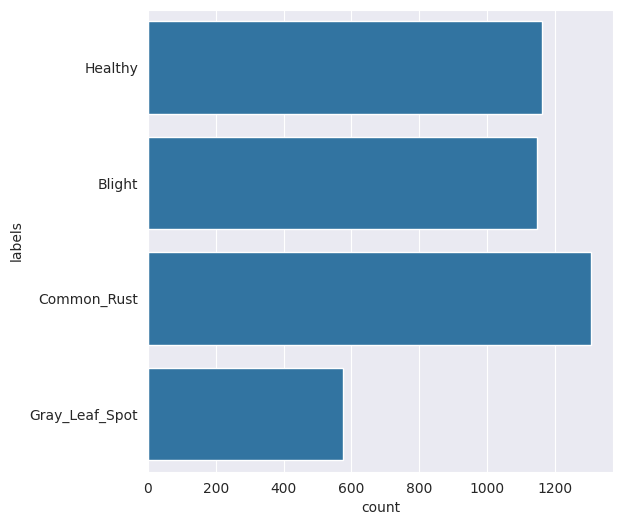

In [10]:
lung_path = "data"

file_name = []
labels = []
full_path = []

for path, subdirs, files in os.walk(lung_path):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

distribution_image = pd.DataFrame({"path":full_path, 'file_name':file_name, "labels":labels})

Label = distribution_image['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)

In [11]:
for distribusion in distribution_image['labels'].unique():
  print(f"Total {distribusion} : {distribution_image[distribution_image['labels'] == distribusion].count()['labels']}")

print("===================================================")
print(f"Total Dataset Image Keseluruhan : {Label.count()}")

Total Healthy : 1162
Total Blight : 1146
Total Common_Rust : 1306
Total Gray_Leaf_Spot : 574
Total Dataset Image Keseluruhan : 4188


In [12]:
df = distribution_image.copy()
df.head()

,path,file_name,labels
0,data/Healthy/Corn_Health (379).jpg,Corn_Health (379).jpg,Healthy
1,data/Healthy/Corn_Health (297).jpg,Corn_Health (297).jpg,Healthy
2,data/Healthy/Corn_Health (93).jpg,Corn_Health (93).jpg,Healthy
3,data/Healthy/Corn_Health (354).jpg,Corn_Health (354).jpg,Healthy
4,data/Healthy/Corn_Health (804).jpg,Corn_Health (804).jpg,Healthy


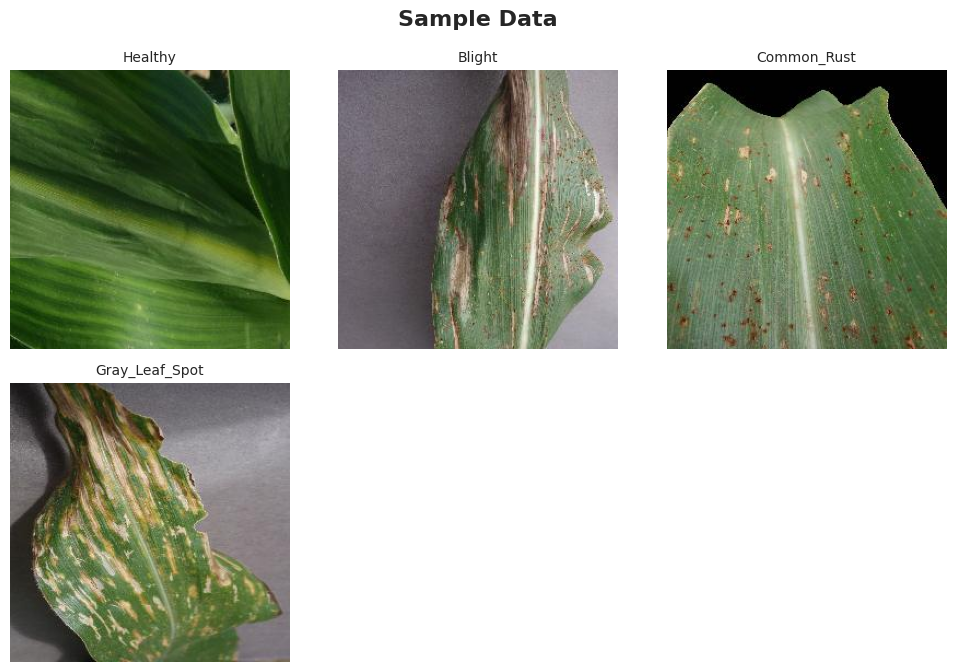

In [13]:
unique_labels = df['labels'].unique()

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
fig.suptitle("Sample Data", fontsize=16, fontweight='bold')

axes = axes.flatten()

# Looping untuk menampilkan gambar sesuai jumlah unique_labels
for i, uniq in enumerate(unique_labels):
    sample_path = df[df['labels'] == uniq]['path'].values[0]

    img = Image.open(sample_path)

    axes[i].imshow(img)
    axes[i].set_title(uniq, fontsize=10)
    axes[i].axis('off')

# Menyembunyikan sisa subplot yang kosong
for j in range(len(unique_labels), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

In [14]:
X= df['path']
y= df['labels']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=True, stratify=y)

In [15]:
df_tr = pd.DataFrame({'path':X_train,'labels':y_train,'set':'train'})
df_te = pd.DataFrame({'path':X_test,'labels':y_test,'set':'test'})
df_all = pd.concat([df_tr, df_te], ignore_index=True)

print('===================================================== \n')
print(df_all.groupby(['set', 'labels']).size(), '\n')
print('===================================================== \n')

print(df_all.sample(5))


set    labels        
test   Blight             229
       Common_Rust        261
       Gray_Leaf_Spot     115
       Healthy            233
train  Blight             917
       Common_Rust       1045
       Gray_Leaf_Spot     459
       Healthy            929
dtype: int64 


                                              path          labels    set
781   data/Gray_Leaf_Spot/Corn_Gray_Spot (434).JPG  Gray_Leaf_Spot  train
4096  data/Common_Rust/Corn_Common_Rust (1179).JPG     Common_Rust   test
1306  data/Gray_Leaf_Spot/Corn_Gray_Spot (528).JPG  Gray_Leaf_Spot  train
3753   data/Common_Rust/Corn_Common_Rust (505).JPG     Common_Rust   test
2834             data/Blight/Corn_Blight (324).JPG          Blight  train


In [16]:
df_all.head()

,path,labels,set
0,data/Healthy/Corn_Health (917).jpg,Healthy,train
1,data/Common_Rust/Corn_Common_Rust (858).JPG,Common_Rust,train
2,data/Common_Rust/Corn_Common_Rust (164).JPG,Common_Rust,train
3,data/Healthy/Corn_Health (763).jpg,Healthy,train
4,data/Gray_Leaf_Spot/Corn_Gray_Spot (315).JPG,Gray_Leaf_Spot,train


In [17]:
datasource_path = lung_path
dataset_path = "new_dataset/"

for index, row in tq(df_all.iterrows()):
    file_path = row['path']
    if os.path.exists(file_path) == False:
            file_path = os.path.join(datasource_path,row['labels'],row['image'].split('.')[0])

    if os.path.exists(os.path.join(dataset_path,row['set'],row['labels'])) == False:
        os.makedirs(os.path.join(dataset_path,row['set'],row['labels']))

    destination_file_name = file_path.split('/')[-1]
    file_dest = os.path.join(dataset_path,row['set'],row['labels'],destination_file_name)

    if os.path.exists(file_dest) == False:
        shutil.copy2(file_path,file_dest)

0it [00:00, ?it/s]

In [18]:
TRAIN_DIR = "new_dataset/train/"
TEST_DIR = "new_dataset/test/"
arr_train = []
arr_test = []

for key, data in enumerate(os.listdir(TRAIN_DIR)):
  dict_train = {"train_name" : f"train_{data}",
                "train_path" : os.path.join(f"{TRAIN_DIR}{data}")}
  arr_train.append(dict_train)
for key, data in enumerate(os.listdir(TEST_DIR)):
  dict_test = {"test_name" : f"test_{data}",
                "test_path" : os.path.join(f"{TEST_DIR}{data}")}
  arr_test.append(dict_test)

for ar_tr in arr_train:
  print(f"Total number of {ar_tr["train_name"].replace("_", " ")} : {len(os.listdir(ar_tr["train_path"]))}")

print("===================================================")

for ar_ts in arr_test:
  print(f"Total number of {ar_ts["test_name"].replace("_", " ")} : {len(os.listdir(ar_ts["test_path"]))}")

Total number of train Healthy : 929
Total number of train Blight : 917
Total number of train Common Rust : 1045
Total number of train Gray Leaf Spot : 459
Total number of test Healthy : 233
Total number of test Blight : 229
Total number of test Common Rust : 261
Total number of test Gray Leaf Spot : 115


In [19]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False
)
class_names = test_dataset.class_names
NUM_CLASSES = len(train_dataset.class_names)
print(f"Jumlah kelas terdeteksi: {NUM_CLASSES}")

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Found 3350 files belonging to 4 classes.
Using 2680 files for training.
Found 3350 files belonging to 4 classes.
Using 670 files for validation.
Found 838 files belonging to 4 classes.
Jumlah kelas terdeteksi: 4


In [20]:
print("Jumlah data latih:", len(train_dataset))
print("Jumlah data validasi:", len(val_dataset))
print("Jumlah data uji:", len(test_dataset))

Jumlah data latih: 84
Jumlah data validasi: 21
Jumlah data uji: 27


In [21]:
print(class_names)

['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


In [22]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Jumlah sampel per kelas (0: Rust, 1: Spot, 2: Blight, 3: Healthy)
samples = [1146, 1306, 574, 1162]
classes = np.array([0, 1, 2, 3])

# Buat array target representatif untuk perhitungan
y = np.repeat(classes, samples)

# Hitung class weights dengan formula 'balanced'
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y)
class_weight_dict = dict(zip(classes, weights))

print(class_weight_dict)

{np.int64(0): np.float64(0.9136125654450262), np.int64(1): np.float64(0.8016845329249617), np.int64(2): np.float64(1.82404181184669), np.int64(3): np.float64(0.9010327022375215)}


In [23]:
data_augmentation = Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2),
    RandomTranslation(height_factor=0.2, width_factor=0.2),
    RandomZoom(0.2),
], name="augmentation_layer")

# LAYER BARU KHUSUS MOBILENETV2 (Rumus: (x / 127.5) - 1 )
# Ini mengubah rentang 0-255 menjadi -1 sampai 1
mobilenet_preprocess = Rescaling(scale=1./127.5, offset=-1, name="mobilenet_rescale")

# Muat Base Model MobileNetV2
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# Rangkai Model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = mobilenet_preprocess(x)         # <--- Masukkan layer rescale di sini!
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_layer (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_rescale (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [24]:
# 1. Buat Custom Callback
class StopAtThreshold(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        # Mengecek apakah akurasi validasi sudah 96% (0.96) atau lebih
        if logs.get('val_accuracy') >= 0.96:
            print("\nTarget akurasi validasi 96% tercapai! Menghentikan training...")
            self.model.stop_training = True

# 2. Inisialisasi Custom Callback
stop_threshold = StopAtThreshold()

# 3. Gabungkan ke dalam callbacks_list
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(filepath='model_padi_mobilenetv2.keras', monitor='val_accuracy', save_best_only=True),
    stop_threshold  # <--- Custom callback ditambahkan di sini
]

In [25]:
print("\n--- MULAI TAHAP 1: FEATURE EXTRACTION ---")
history_1 = model.fit(train_dataset, validation_data=val_dataset, epochs=15, callbacks=callbacks_list, class_weight=class_weight_dict)


--- MULAI TAHAP 1: FEATURE EXTRACTION ---
Epoch 1/15
84/84 ━━━━━━━━━━━━━━━━━━━━ 22s 102ms/step - accuracy: 0.6873 - loss: 0.8352 - val_accuracy: 0.8896 - val_loss: 0.3116 - learning_rate: 0.0010
Epoch 2/15
84/84 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.8310 - loss: 0.4553 - val_accuracy: 0.8746 - val_loss: 0.3129 - learning_rate: 0.0010
Epoch 3/15
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.8604 - loss: 0.3829 - val_accuracy: 0.8940 - val_loss: 0.2769 - learning_rate: 0.0010
Epoch 4/15
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.8683 - loss: 0.3649 - val_accuracy: 0.8731 - val_loss: 0.3123 - learning_rate: 0.0010
Epoch 5/15
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.8739 - loss: 0.3550 - val_accuracy: 0.8493 - val_loss: 0.3618 - learning_rate: 0.0010
Epoch 6/15
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.8884 - loss: 0.3226 - val_accuracy: 0.8940 - val_loss: 0.2693 - learning_rate: 0.0010
Epoch 7/15
84/84 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/ste

In [26]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.9224 - loss: 0.2114
--------------------------------------------------
TEST ACCURACY: 0.9224 (92.24%)
TEST LOSS:     0.2114
--------------------------------------------------


In [27]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step

CLASSIFICATION REPORT:
                precision    recall  f1-score   support

        Blight       0.89      0.86      0.88       229
   Common_Rust       0.97      0.97      0.97       261
Gray_Leaf_Spot       0.75      0.81      0.78       115
       Healthy       0.99      0.99      0.99       233

      accuracy                           0.92       838
     macro avg       0.90      0.91      0.90       838
  weighted avg       0.92      0.92      0.92       838



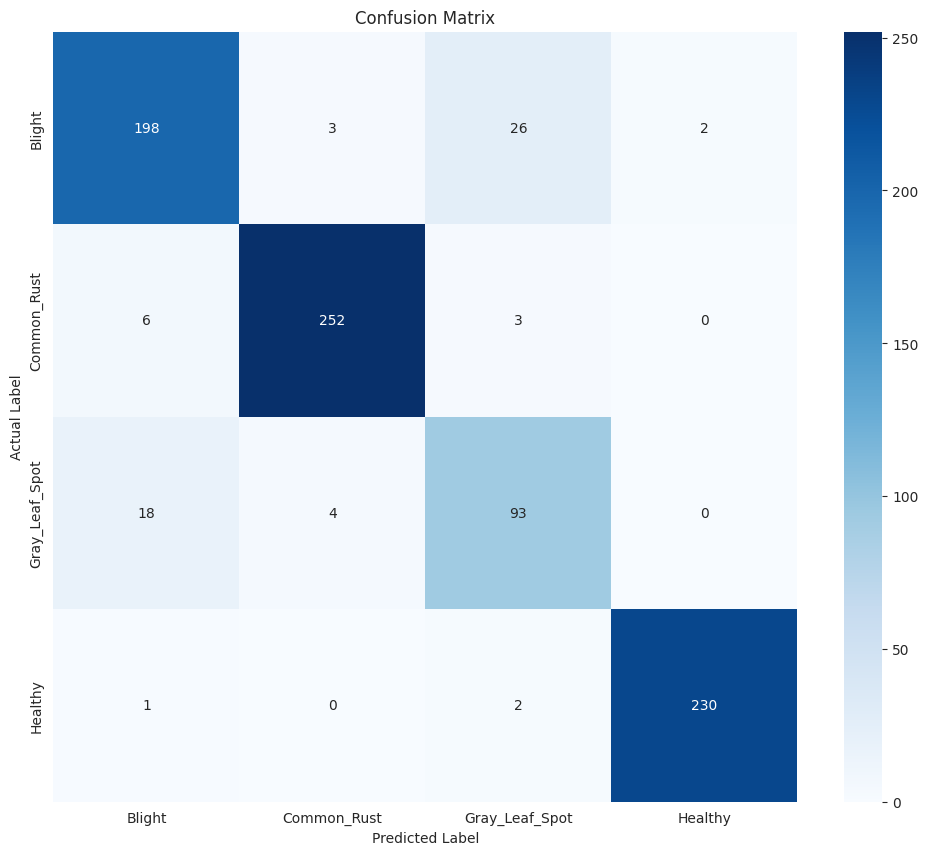

In [28]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

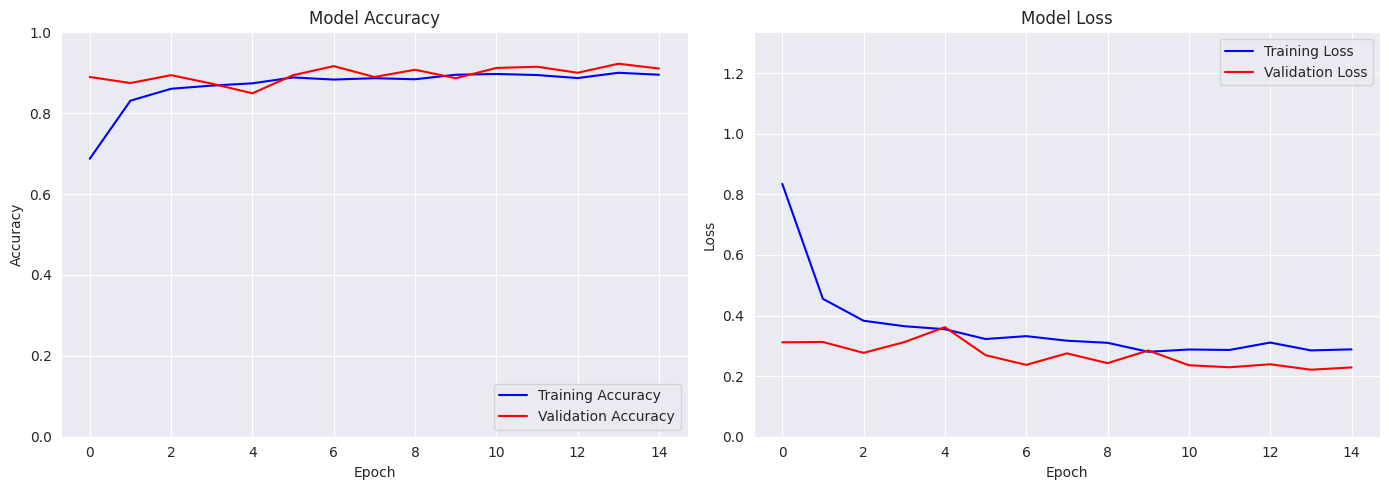

In [29]:
if 'history_1' in locals():
    acc = history_1.history['accuracy']
    val_acc = history_1.history['val_accuracy']
    loss = history_1.history['loss']
    val_loss = history_1.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [30]:
shutil.copy("/content/model_padi_mobilenetv2.keras", "/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/v2/Corn_MobileNetV2_pre-trained.keras")

'/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/v2/Corn_MobileNetV2_pre-trained.keras'

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


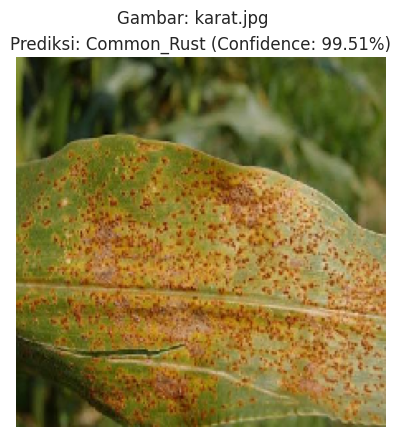

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


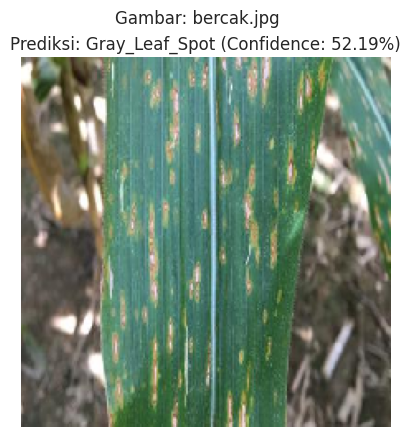

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


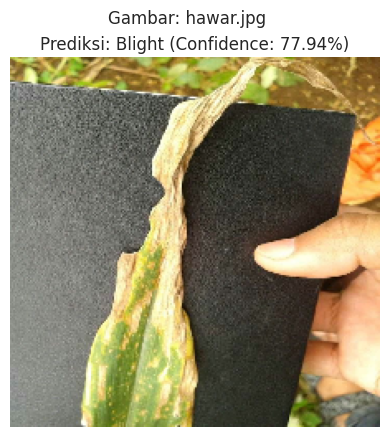

In [31]:
def predict_image(img_path, model, class_names):
    # 1. Muat gambar dan pastikan ukurannya sesuai dengan input model
    img = image.load_img(img_path, target_size=(224, 224))
    img_filename = os.path.basename(img_path)

    # 2. Ubah gambar menjadi array
    img_array = image.img_to_array(img)

    # 3. Tambahkan dimensi batch (dari (224, 224, 3) menjadi (1, 224, 224, 3))
    img_array = np.expand_dims(img_array, axis=0)

    # CATATAN: Rescale (img_array /= 255.0) sengaja ditiadakan untuk EfficientNet

    # 4. Lakukan prediksi
    predictions = model.predict(img_array)

    # 5. Ekstrak hasil
    predicted_class = np.argmax(predictions[0])
    confidence = np.max(predictions[0])

    # print(f'Predicted: {class_names[predicted_class]} (Confidence: {confidence:.2%})')
    plt.imshow(img)
    plt.title(f"Prediksi: {class_names[predicted_class]} (Confidence: {confidence:.2%})")
    plt.suptitle(f"Gambar: {img_filename}")
    plt.axis("off")
    plt.show()

    # Opsional: Kembalikan nilai jika ingin digunakan di variabel lain
    return class_names[predicted_class], confidence

for i in os.listdir("/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Sample"):
  predict_image(f"/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Sample/{i}", model, class_names)

In [32]:
print("\n--- MULAI TAHAP 2: FINE TUNING ---")
base_model.trainable = True

# Biarkan Batch Normalization membeku
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # LR SANGAT KECIL
              loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()


--- MULAI TAHAP 2: FINE TUNING ---


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_layer (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_rescale (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 2,194,884 (8.37 MB)

 Non-trainable params: 68,224 (266.50 KB)

In [33]:
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(filepath='model_padi_mobilenetv2.keras', monitor='val_accuracy', save_best_only=True),
]

In [34]:
history_2 = model.fit(train_dataset, validation_data=val_dataset, epochs=20, callbacks=callbacks_list, class_weight=class_weight_dict)

Epoch 1/20
84/84 ━━━━━━━━━━━━━━━━━━━━ 25s 172ms/step - accuracy: 0.8985 - loss: 0.2842 - val_accuracy: 0.9224 - val_loss: 0.2213 - learning_rate: 1.0000e-05
Epoch 2/20
84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step - accuracy: 0.9071 - loss: 0.2497 - val_accuracy: 0.9239 - val_loss: 0.2039 - learning_rate: 1.0000e-05
Epoch 3/20
84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 138ms/step - accuracy: 0.9138 - loss: 0.2478 - val_accuracy: 0.9239 - val_loss: 0.1808 - learning_rate: 1.0000e-05
Epoch 4/20
84/84 ━━━━━━━━━━━━━━━━━━━━ 13s 152ms/step - accuracy: 0.9112 - loss: 0.2436 - val_accuracy: 0.9373 - val_loss: 0.1676 - learning_rate: 1.0000e-05
Epoch 5/20
84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 141ms/step - accuracy: 0.9160 - loss: 0.2272 - val_accuracy: 0.9299 - val_loss: 0.1880 - learning_rate: 1.0000e-05
Epoch 6/20
84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step - accuracy: 0.9220 - loss: 0.2136 - val_accuracy: 0.9343 - val_loss: 0.1791 - learning_rate: 1.0000e-05
Epoch 7/20
84/84 ━━━━━━━━━━━━━━━━━━━━ 13s 154ms/step - acc

In [35]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.9427 - loss: 0.1707
--------------------------------------------------
TEST ACCURACY: 0.9427 (94.27%)
TEST LOSS:     0.1707
--------------------------------------------------


In [36]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step

CLASSIFICATION REPORT:
                precision    recall  f1-score   support

        Blight       0.92      0.90      0.91       229
   Common_Rust       0.97      1.00      0.98       261
Gray_Leaf_Spot       0.81      0.80      0.81       115
       Healthy       1.00      1.00      1.00       233

      accuracy                           0.94       838
     macro avg       0.92      0.92      0.92       838
  weighted avg       0.94      0.94      0.94       838



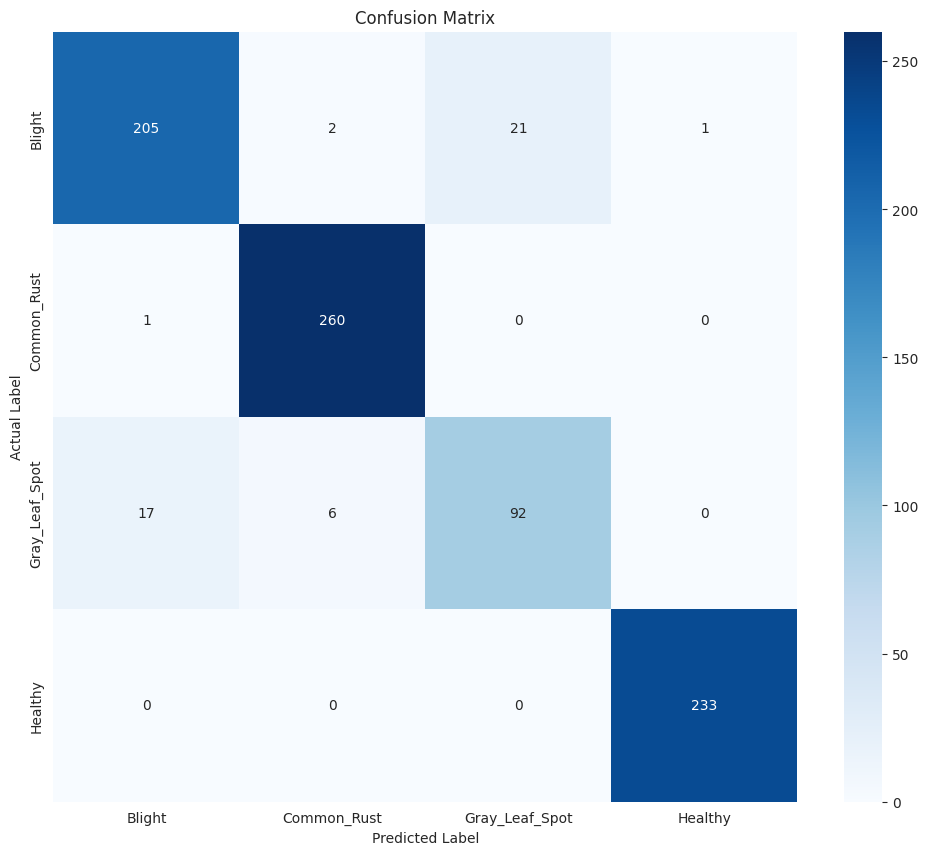

In [37]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

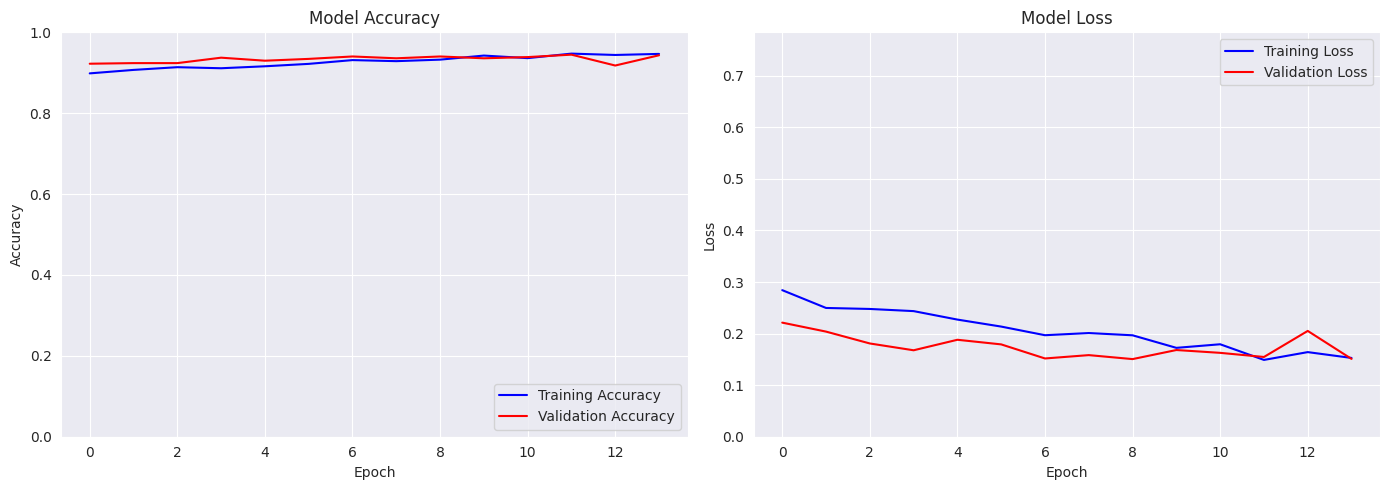

In [38]:
if 'history_2' in locals():
    acc = history_2.history['accuracy']
    val_acc = history_2.history['val_accuracy']
    loss = history_2.history['loss']
    val_loss = history_2.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [39]:
shutil.copy("/content/model_padi_mobilenetv2.keras", "/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/v2/Corn_MobileNetV2_fine-tuning.keras")

'/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/v2/Corn_MobileNetV2_fine-tuning.keras'

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


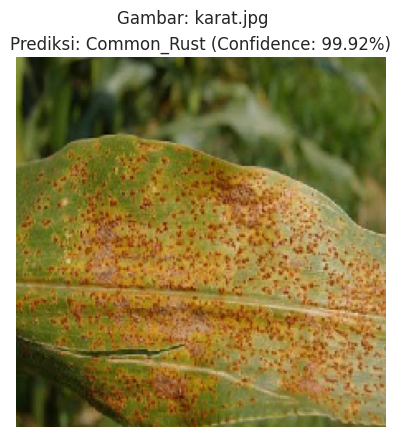

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


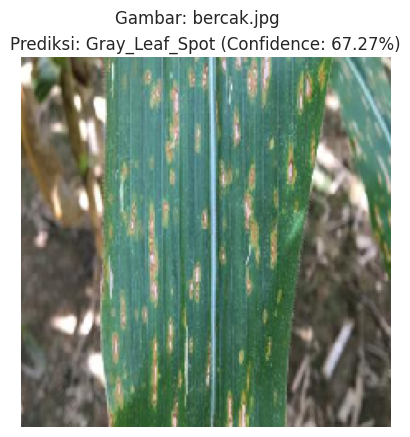

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


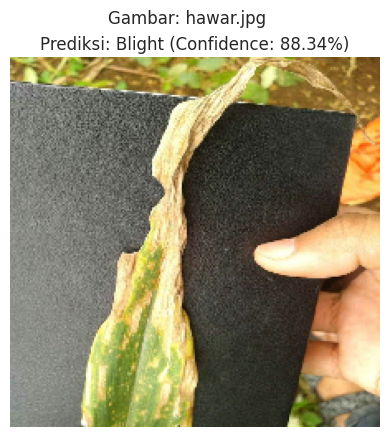

In [40]:
for i in os.listdir("/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Sample"):
  predict_image(f"/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Sample/{i}", model, class_names)

In [41]:
class_names

['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']

In [42]:
model = tf.keras.models.load_model('/content/model_padi_mobilenetv2.keras')
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT] # Optimasi ukuran
tflite_model = converter.convert()

with open('/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/v2/Corn_MobileNetV2_fine-tuning.tflite', 'wb') as f:
    f.write(tflite_model)

Saved artifact at '/tmp/tmp1vlsvqvo'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134236586904080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134233198069136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134233198070480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134236587534544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134233198080656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134233198082768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134233198080464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134233198070864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134233198079120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134233198078736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1342331980677